# Inteligencia artificial clásica · Búsqueda con adversario

Cómo decide una máquina en un juego de dos jugadores por turnos y con información perfecta: el juego como un problema de búsqueda (estado inicial, jugadas, transición, estado terminal y utilidad), minimax, la tabla de transposiciones, la poda alfa-beta y cuánto ahorra según el orden de las jugadas, la búsqueda con profundidad limitada y una función de evaluación (en el Conecta 4) y la búsqueda en árbol de Monte Carlo (MCTS con UCT), comparada con minimax. El tres en raya jugable contra el ordenador está en *Funciones*; aquí interesa la técnica, que se escribe una sola vez y sirve para cualquier juego que cumpla la misma interfaz.

In [1]:
import math
import random
from collections import Counter
from functools import cache

import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (6, 3.2), "figure.dpi": 80})

## 1. El juego como problema de búsqueda

Definir dos juegos con la misma interfaz: `inicial`, `jugadas(e)`, `aplicar(e, jugada)`, `terminal(e)`, `utilidad(e)` (desde el punto de vista del primer jugador, MAX: $+1$, $0$ o $-1$) y `juega_max(e)`. El primero es el tres en raya; el segundo, el juego de las fichas: hay $n$ fichas en la mesa, cada jugador retira 1, 2 o 3 y gana quien se lleva la última. Recorrer el árbol completo del tres en raya y comprobar que hay 255 168 partidas distintas: 131 184 las gana X, 77 904 O y 46 080 acaban en tablas.

In [2]:
LINEAS = [(0, 1, 2), (3, 4, 5), (6, 7, 8), (0, 3, 6), (1, 4, 7), (2, 5, 8), (0, 4, 8), (2, 4, 6)]


def ganador(tablero):
    for a, b, c in LINEAS:
        if tablero[a] != "." and tablero[a] == tablero[b] == tablero[c]:
            return tablero[a]
    return None


class TresEnRaya:
    inicial = (".........", "X")

    def jugadas(self, e):
        return [i for i, c in enumerate(e[0]) if c == "."]

    def aplicar(self, e, i):
        tablero, turno = e
        return tablero[:i] + turno + tablero[i + 1:], "O" if turno == "X" else "X"

    def terminal(self, e):
        return ganador(e[0]) is not None or "." not in e[0]

    def utilidad(self, e):
        return {"X": 1, "O": -1, None: 0}[ganador(e[0])]

    def juega_max(self, e):
        return e[1] == "X"


class Fichas:
    def __init__(self, n):
        self.inicial = (n, True)

    def jugadas(self, e):
        return [k for k in (1, 2, 3) if k <= e[0]]

    def aplicar(self, e, k):
        return e[0] - k, not e[1]

    def terminal(self, e):
        return e[0] == 0

    def utilidad(self, e):
        # Sin fichas, el que tiene el turno ha perdido: el rival se llevó la última
        return -1 if e[1] else 1

    def juega_max(self, e):
        return e[1]


def contar_partidas(juego, e, conteo):
    if juego.terminal(e):
        conteo[juego.utilidad(e)] += 1
        return
    for m in juego.jugadas(e):
        contar_partidas(juego, juego.aplicar(e, m), conteo)


tres = TresEnRaya()
conteo = Counter()
contar_partidas(tres, tres.inicial, conteo)
print(f"Partidas: {conteo.total()} (gana X: {conteo[1]}, gana O: {conteo[-1]}, tablas: {conteo[0]})")
assert (conteo.total(), conteo[1], conteo[-1], conteo[0]) == (255_168, 131_184, 77_904, 46_080)

conteo = Counter()
contar_partidas(Fichas(10), Fichas(10).inicial, conteo)
print("Fichas(10):", dict(conteo))

Partidas: 255168 (gana X: 131184, gana O: 77904, tablas: 46080)
Fichas(10): {-1: 137, 1: 137}


## 2. Minimax

Escribir `minimax(juego, e)`, que devuelva el valor del estado suponiendo que los dos juegan perfectamente (MAX maximiza la utilidad y MIN la minimiza) y cuente los nodos visitados. Comprobar que el tres en raya acaba en tablas, que recorre los 549 946 nodos del árbol y que en el juego de las fichas pierde quien empieza exactamente cuando $n$ es múltiplo de 4 (tras cada jugada del rival se puede completar un grupo de 4).

In [3]:
def minimax(juego, e, nodos):
    nodos[0] += 1
    if juego.terminal(e):
        return juego.utilidad(e)
    valores = [minimax(juego, juego.aplicar(e, m), nodos) for m in juego.jugadas(e)]
    return max(valores) if juego.juega_max(e) else min(valores)


nodos = [0]
print("Valor del tres en raya:", minimax(tres, tres.inicial, nodos), "| nodos:", nodos[0])
assert nodos[0] == 549_946

for n in range(1, 17):
    juego = Fichas(n)
    assert (minimax(juego, juego.inicial, [0]) == -1) == (n % 4 == 0)
print("Fichas: pierde el primero con n =", [n for n in range(1, 17) if minimax(Fichas(n), Fichas(n).inicial, [0]) == -1])

Valor del tres en raya: 0 | nodos: 549946
Fichas: pierde el primero con n = [4, 8, 12, 16]


## 3. Tabla de transposiciones

Muchas partidas llegan a la misma posición por caminos distintos (X en 0 y luego en 4 es lo mismo que X en 4 y luego en 0). Escribir `minimax_memo`, que guarde el valor de cada estado ya resuelto en un diccionario, y comprobar que el tres en raya solo tiene 5478 posiciones alcanzables, frente a los 549 946 nodos del árbol. Contar cuántas de ellas son victoria, tablas o derrota para X con juego perfecto.

In [4]:
def minimax_memo(juego, e, tabla):
    if e not in tabla:
        if juego.terminal(e):
            tabla[e] = juego.utilidad(e)
        else:
            valores = [minimax_memo(juego, juego.aplicar(e, m), tabla) for m in juego.jugadas(e)]
            tabla[e] = max(valores) if juego.juega_max(e) else min(valores)
    return tabla[e]


VALORES = {}
minimax_memo(tres, tres.inicial, VALORES)
print("Posiciones distintas:", len(VALORES))
print("Valor con juego perfecto:", dict(sorted(Counter(VALORES.values()).items())))
assert len(VALORES) == 5478 and VALORES[tres.inicial] == 0

Posiciones distintas: 5478
Valor con juego perfecto: {-1: 1474, 0: 1068, 1: 2936}


## 4. Poda alfa-beta

Alfa-beta lleva dos cotas: $\alpha$, lo mínimo que MAX ya tiene asegurado, y $\beta$, lo máximo que MIN ya tiene asegurado. Cuando $\alpha \ge \beta$ el resto de hermanos no puede cambiar la decisión y se poda. Escribir `alfabeta(juego, e, orden)` contando nodos, comprobar que da el mismo valor que minimax en 300 posiciones al azar y comparar los nodos visitados desde el tablero vacío con el orden natural de las casillas y con un orden que prueba antes el centro y las esquinas.

In [5]:
def alfabeta(juego, e, nodos, alfa=-math.inf, beta=math.inf, orden=None):
    nodos[0] += 1
    if juego.terminal(e):
        return juego.utilidad(e)
    jugadas = juego.jugadas(e) if orden is None else sorted(juego.jugadas(e), key=orden)
    if juego.juega_max(e):
        valor = -math.inf
        for m in jugadas:
            valor = max(valor, alfabeta(juego, juego.aplicar(e, m), nodos, alfa, beta, orden))
            alfa = max(alfa, valor)
            if alfa >= beta:
                break
    else:
        valor = math.inf
        for m in jugadas:
            valor = min(valor, alfabeta(juego, juego.aplicar(e, m), nodos, alfa, beta, orden))
            beta = min(beta, valor)
            if alfa >= beta:
                break
    return valor


rng = random.Random(4)
for e in rng.sample(sorted(VALORES), 300):
    assert alfabeta(tres, e, [0]) == VALORES[e]

prioridad = [1, 2, 1, 2, 0, 2, 1, 2, 1]
print(f"{'búsqueda':<28} {'nodos':>8}")
for nombre, funcion, orden in [("minimax", minimax, None), ("alfa-beta, orden natural", alfabeta, None),
                               ("alfa-beta, centro y esquinas", alfabeta, prioridad.__getitem__)]:
    nodos = [0]
    valor = funcion(tres, tres.inicial, nodos) if orden is None else funcion(tres, tres.inicial, nodos, orden=orden)
    assert valor == 0
    print(f"{nombre:<28} {nodos[0]:>8}")

búsqueda                        nodos


minimax                        549946
alfa-beta, orden natural        18297
alfa-beta, centro y esquinas     7275


## 5. Alfa-beta en árboles aleatorios

Generar árboles de juego uniformes con factor de ramificación $b$, profundidad $d$ y hojas con valores aleatorios (listas anidadas, semilla fija). Contar las hojas que evalúa alfa-beta con los hijos en orden aleatorio y con el orden perfecto (cada nodo prueba primero su mejor hijo). Con el orden perfecto, Knuth y Moore demostraron que se evalúan exactamente $b^{\lceil d/2 \rceil} + b^{\lfloor d/2 \rfloor} - 1$ hojas, frente a las $b^d$ de minimax: es como duplicar la profundidad alcanzable. Comprobarlo y comprobar que el valor coincide siempre con minimax.

In [6]:
def arbol_aleatorio(b, d, rng):
    return rng.random() if d == 0 else [arbol_aleatorio(b, d - 1, rng) for _ in range(b)]


def valor_minimax(nodo, es_max=True):
    if not isinstance(nodo, list):
        return nodo
    valores = [valor_minimax(h, not es_max) for h in nodo]
    return max(valores) if es_max else min(valores)


def ordenar_perfecto(nodo, es_max=True):
    if not isinstance(nodo, list):
        return nodo
    hijos = [ordenar_perfecto(h, not es_max) for h in nodo]
    return sorted(hijos, key=lambda h: valor_minimax(h, not es_max), reverse=es_max)


def alfabeta_arbol(nodo, hojas, es_max=True, alfa=-math.inf, beta=math.inf):
    if not isinstance(nodo, list):
        hojas[0] += 1
        return nodo
    valor = -math.inf if es_max else math.inf
    for hijo in nodo:
        v = alfabeta_arbol(hijo, hojas, not es_max, alfa, beta)
        if es_max:
            valor, alfa = max(valor, v), max(alfa, v)
        else:
            valor, beta = min(valor, v), min(beta, v)
        if alfa >= beta:
            break
    return valor


rng = random.Random(5)
print(f"{'b':>2} {'d':>2} {'minimax':>8} {'aleatorio':>10} {'perfecto':>9} {'Knuth-Moore':>12}")
for b, d in [(2, 8), (3, 6), (4, 6), (5, 5), (8, 4)]:
    arbol = arbol_aleatorio(b, d, rng)
    h_aleatorio, h_perfecto = [0], [0]
    assert alfabeta_arbol(arbol, h_aleatorio) == valor_minimax(arbol)
    assert alfabeta_arbol(ordenar_perfecto(arbol), h_perfecto) == valor_minimax(arbol)
    cota = b ** math.ceil(d / 2) + b ** (d // 2) - 1
    assert h_perfecto[0] == cota
    print(f"{b:>2} {d:>2} {b ** d:>8} {h_aleatorio[0]:>10} {h_perfecto[0]:>9} {cota:>12}")

 b  d  minimax  aleatorio  perfecto  Knuth-Moore
 2  8      256        135        31           31
 3  6      729        269        53           53
 4  6     4096       1163       127          127
 5  5     3125        854       149          149
 8  4     4096        986       127          127


## 6. Ganar cuanto antes

Con utilidades $+1$, $0$ y $-1$, minimax no distingue entre ganar ya y ganar dentro de tres jugadas, y puede «entretenerse». Escribir `mejor_jugada(e, rapida)` que, en la versión rápida, puntúe la victoria con $10 - \text{jugadas hechas}$ (y la derrota con lo contrario), de modo que prefiera ganar pronto y perder tarde. Buscar una posición en la que la versión simple no gane de inmediato pudiendo hacerlo y comprobar que la rápida siempre lo hace.

In [7]:
@cache
def valor_rapido(e):
    tablero, _ = e
    if tres.terminal(e):
        return tres.utilidad(e) * (10 - (9 - tablero.count(".")))
    valores = [valor_rapido(tres.aplicar(e, m)) for m in tres.jugadas(e)]
    return max(valores) if tres.juega_max(e) else min(valores)


def mejor_jugada(e, rapida=False):
    valor = valor_rapido if rapida else VALORES.__getitem__
    elegir = max if tres.juega_max(e) else min
    return elegir(tres.jugadas(e), key=lambda m: valor(tres.aplicar(e, m)))


def dibujar(tablero):
    return "\n".join(" ".join(tablero[f * 3:f * 3 + 3]) for f in range(3))


entretenidas = []
for e in VALORES:
    if tres.terminal(e):
        continue
    inmediatas = [m for m in tres.jugadas(e) if ganador(tres.aplicar(e, m)[0])]
    if inmediatas:
        assert mejor_jugada(e, rapida=True) in inmediatas
        if mejor_jugada(e) not in inmediatas:
            entretenidas.append(e)
print(f"Posiciones en las que minimax simple no remata: {len(entretenidas)}")
e = min(entretenidas)
print(dibujar(e[0]), f"\nJuega {e[1]}: simple → casilla {mejor_jugada(e)}, rápida → casilla {mejor_jugada(e, rapida=True)}")

Posiciones en las que minimax simple no remata: 392
. . .
. . X
O O X 
Juega X: simple → casilla 0, rápida → casilla 2


## 7. Nim de varios montones

En el Nim hay varios montones y cada jugador retira las fichas que quiera (al menos una) de un solo montón; gana quien se lleva la última. Resolverlo con minimax y memoria (un estado es la tupla ordenada de montones, porque el orden no importa) y comprobar el teorema de Bouton: el jugador que mueve pierde exactamente cuando el XOR de los montones es 0. Escribir `jugada_ganadora`, que deje al rival con XOR 0, y comprobar que el rival queda siempre en una posición perdedora.

In [8]:
@cache
def gana_quien_mueve(montones):
    for i, m in enumerate(montones):
        for quitar in range(1, m + 1):
            siguiente = tuple(sorted(montones[:i] + (m - quitar,) + montones[i + 1:]))
            if not gana_quien_mueve(siguiente):
                return True
    return False


def xor(montones):
    resultado = 0
    for m in montones:
        resultado ^= m
    return resultado


def jugada_ganadora(montones):
    x = xor(montones)
    for i, m in enumerate(montones):
        if m ^ x < m:
            return i, m - (m ^ x)
    return None


from itertools import product

total = 0
for montones in [*product(range(8), repeat=3), *product(range(5), repeat=4)]:
    estado = tuple(sorted(montones))
    assert gana_quien_mueve(estado) == (xor(estado) != 0)
    if (jugada := jugada_ganadora(montones)) is not None:
        i, quitar = jugada
        tras = tuple(sorted(montones[:i] + (montones[i] - quitar,) + montones[i + 1:]))
        assert xor(tras) == 0 and not gana_quien_mueve(tras)
    total += 1
print(f"Bouton comprobado en {total} posiciones")
print("Montones (3, 4, 5): XOR =", xor((3, 4, 5)), "→ quitar", jugada_ganadora((3, 4, 5))[1], "del montón", jugada_ganadora((3, 4, 5))[0])

Bouton comprobado en 1137 posiciones
Montones (3, 4, 5): XOR = 2 → quitar 2 del montón 0


## 8. Conecta 4 con profundidad limitada

El Conecta 4 (6 filas y 7 columnas) es demasiado grande para minimax completo. Implementarlo con la misma interfaz, guardando la última jugada para comprobar solo las líneas que pasan por ella, y escribir una función de evaluación para las posiciones no terminales: para cada ventana de 4 casillas alineadas que solo tiene fichas de un jugador, sumar (o restar) 1, 4 o 16 según tenga 1, 2 o 3 fichas, más un pequeño premio por ocupar la columna central. Escribir `alfabeta_limitado(e, profundidad)` probando primero las columnas centrales y comprobar en posiciones de prueba que remata una victoria en una jugada y que tapa la del rival.

In [9]:
FILAS, COLUMNAS = 6, 7
DIRECCIONES = [(1, 0), (0, 1), (1, 1), (1, -1)]
VENTANAS = [[(c + k * dc, f + k * df) for k in range(4)]
            for c in range(COLUMNAS) for f in range(FILAS) for dc, df in DIRECCIONES
            if 0 <= c + 3 * dc < COLUMNAS and 0 <= f + 3 * df < FILAS]
ORDEN_COLUMNAS = [3, 2, 4, 1, 5, 0, 6]


class Conecta4:
    inicial = (("",) * COLUMNAS, "X", None)

    def jugadas(self, e):
        return [c for c in ORDEN_COLUMNAS if len(e[0][c]) < FILAS]

    def aplicar(self, e, c):
        columnas, turno, _ = e
        nuevas = columnas[:c] + (columnas[c] + turno,) + columnas[c + 1:]
        return nuevas, "O" if turno == "X" else "X", (c, len(columnas[c]))

    def ganador(self, e):
        columnas, _, ultima = e
        if ultima is None:
            return None
        c, f = ultima
        ficha = columnas[c][f]
        for dc, df in DIRECCIONES:
            seguidas = 1
            for signo in (1, -1):
                k = 1
                while True:
                    cc, ff = c + signo * k * dc, f + signo * k * df
                    if not (0 <= cc < COLUMNAS and 0 <= ff < len(columnas[cc])) or columnas[cc][ff] != ficha:
                        break
                    seguidas += 1
                    k += 1
            if seguidas >= 4:
                return ficha
        return None

    def terminal(self, e):
        return self.ganador(e) is not None or all(len(col) == FILAS for col in e[0])

    def utilidad(self, e):
        return {"X": 1, "O": -1, None: 0}[self.ganador(e)]

    def juega_max(self, e):
        return e[1] == "X"


def evaluar(e):
    columnas = e[0]
    puntos = {0: 0, 1: 1, 2: 4, 3: 16}
    total = 0
    for ventana in VENTANAS:
        fichas = [columnas[c][f] if f < len(columnas[c]) else "." for c, f in ventana]
        x, o = fichas.count("X"), fichas.count("O")
        if o == 0:
            total += puntos[x]
        elif x == 0:
            total -= puntos[o]
    return total + 3 * (columnas[3].count("X") - columnas[3].count("O"))


conecta = Conecta4()


def alfabeta_limitado(e, profundidad, alfa=-math.inf, beta=math.inf, nodos=None):
    if nodos is not None:
        nodos[0] += 1
    if conecta.terminal(e):
        # Las victorias más cercanas valen más
        return 10_000 * conecta.utilidad(e) * (profundidad + 1)
    if profundidad == 0:
        return evaluar(e)
    es_max = conecta.juega_max(e)
    valor = -math.inf if es_max else math.inf
    for c in conecta.jugadas(e):
        v = alfabeta_limitado(conecta.aplicar(e, c), profundidad - 1, alfa, beta, nodos)
        if es_max:
            valor, alfa = max(valor, v), max(alfa, v)
        else:
            valor, beta = min(valor, v), min(beta, v)
        if alfa >= beta:
            break
    return valor


def jugador_alfabeta(profundidad):
    def elegir(e):
        elegir_mejor = max if conecta.juega_max(e) else min
        return elegir_mejor(conecta.jugadas(e), key=lambda c: alfabeta_limitado(conecta.aplicar(e, c), profundidad - 1))
    return elegir


def desde_jugadas(columnas_jugadas):
    e = conecta.inicial
    for c in columnas_jugadas:
        e = conecta.aplicar(e, c)
    return e


def dibujar_c4(e):
    columnas = e[0]
    return "\n".join(" ".join(columnas[c][f] if f < len(columnas[c]) else "." for c in range(COLUMNAS))
                     for f in range(FILAS - 1, -1, -1))


rematar = desde_jugadas([0, 0, 1, 1, 2, 2])  # X tiene tres en la fila de abajo
tapar = desde_jugadas([6, 0, 6, 1, 5, 2])  # O amenaza con la columna 3
print(dibujar_c4(rematar), "\n")
for nombre, e, esperado in [("rematar", rematar, 3), ("tapar", tapar, 3)]:
    jugada = jugador_alfabeta(4)(e)
    print(f"{nombre}: juega {e[1]} en la columna {jugada}")
    assert jugada == esperado
print("Ventanas de 4:", len(VENTANAS))
assert len(VENTANAS) == 69

. . . . . . .
. . . . . . .
. . . . . . .
. . . . . . .
O O O . . . .
X X X . . . . 

rematar: juega X en la columna 3
tapar: juega X en la columna 3
Ventanas de 4: 69


## 9. Torneo de profundidades

Enfrentar en el Conecta 4 a un jugador aleatorio y a jugadores alfa-beta de profundidad 1, 2 y 4 (con semillas fijas para el aleatorio), alternando quién empieza, y mostrar la tabla de resultados. Comprobar que la profundidad 4 no pierde nunca contra el aleatorio y contar los nodos que visita alfa-beta en la primera jugada según la profundidad, para ver el crecimiento exponencial.

In [10]:
def jugar(juego, jugador_x, jugador_o):
    e = juego.inicial
    while not juego.terminal(e):
        e = juego.aplicar(e, (jugador_x if juego.juega_max(e) else jugador_o)(e))
    return juego.utilidad(e)


def jugador_aleatorio(semilla):
    rng = random.Random(semilla)
    return lambda e: rng.choice(conecta.jugadas(e))


resultados = {}
for nombre_a, nombre_b, crear_a, crear_b, partidas in [
    ("prof. 4", "aleatorio", lambda s: jugador_alfabeta(4), jugador_aleatorio, 4),
    ("prof. 2", "aleatorio", lambda s: jugador_alfabeta(2), jugador_aleatorio, 4),
    ("prof. 4", "prof. 1", lambda s: jugador_alfabeta(4), lambda s: jugador_alfabeta(1), 2),
    ("prof. 4", "prof. 2", lambda s: jugador_alfabeta(4), lambda s: jugador_alfabeta(2), 2),
]:
    marcador = Counter()
    for k in range(partidas):
        a, b = crear_a(k), crear_b(100 + k)
        if k % 2 == 0:
            marcador[{1: nombre_a, -1: nombre_b, 0: "tablas"}[jugar(conecta, a, b)]] += 1
        else:
            marcador[{1: nombre_b, -1: nombre_a, 0: "tablas"}[jugar(conecta, b, a)]] += 1
    resultados[(nombre_a, nombre_b)] = marcador
    print(f"{nombre_a} contra {nombre_b:<10} → {nombre_a}: {marcador[nombre_a]}, {nombre_b}: {marcador[nombre_b]}, tablas: {marcador['tablas']}")
assert resultados[("prof. 4", "aleatorio")]["aleatorio"] == 0

print(f"\n{'profundidad':>11} {'nodos':>7}")
for p in range(1, 7):
    nodos = [0]
    alfabeta_limitado(conecta.inicial, p, nodos=nodos)
    print(f"{p:>11} {nodos[0]:>7}")

prof. 4 contra aleatorio  → prof. 4: 4, aleatorio: 0, tablas: 0
prof. 2 contra aleatorio  → prof. 2: 4, aleatorio: 0, tablas: 0
prof. 4 contra prof. 1    → prof. 4: 2, prof. 1: 0, tablas: 0


prof. 4 contra prof. 2    → prof. 4: 1, prof. 2: 1, tablas: 0

profundidad   nodos
          1       8
          2      21
          3      76
          4     173
          5     775
          6    1249


## 10. Búsqueda en árbol de Monte Carlo

MCTS no necesita función de evaluación: construye poco a poco un árbol y estima el valor de cada jugada con partidas aleatorias. Cada iteración tiene cuatro fases: **selección** (bajar eligiendo el hijo que maximiza UCT, $\frac{w_i}{n_i} + c\sqrt{\frac{\ln N}{n_i}}$, que equilibra explotar lo que va bien y explorar lo poco visitado), **expansión** (añadir un hijo nuevo), **simulación** (jugar al azar hasta el final) y **retropropagación** (sumar el resultado en el camino, desde el punto de vista de quien hizo cada jugada). Escribir `mcts(juego, e, iteraciones, rng)` genérico, que devuelva la jugada más visitada, y comprobar en el tres en raya que, con 2000 iteraciones, elige una jugada óptima (según la tabla de minimax) en casi todas las posiciones de una muestra.

In [11]:
class Nodo:
    def __init__(self, estado, padre=None, jugada=None, juego=None):
        self.estado, self.padre, self.jugada = estado, padre, jugada
        self.hijos = []
        self.sin_probar = [] if juego.terminal(estado) else list(juego.jugadas(estado))
        self.visitas, self.victorias = 0, 0.0

    def uct(self, c):
        return self.victorias / self.visitas + c * math.sqrt(math.log(self.padre.visitas) / self.visitas)


def mcts(juego, e, iteraciones, rng, c=math.sqrt(2)):
    raiz = Nodo(e, juego=juego)
    for _ in range(iteraciones):
        nodo = raiz
        while not nodo.sin_probar and nodo.hijos:
            nodo = max(nodo.hijos, key=lambda h: h.uct(c))
        if nodo.sin_probar:
            jugada = nodo.sin_probar.pop(rng.randrange(len(nodo.sin_probar)))
            hijo = Nodo(juego.aplicar(nodo.estado, jugada), nodo, jugada, juego)
            nodo.hijos.append(hijo)
            nodo = hijo
        estado = nodo.estado
        while not juego.terminal(estado):
            estado = juego.aplicar(estado, rng.choice(juego.jugadas(estado)))
        resultado = juego.utilidad(estado)
        while nodo.padre is not None:
            # Premio para quien hizo la jugada que lleva a este nodo, en [0, 1]
            mueve_max = juego.juega_max(nodo.padre.estado)
            nodo.visitas += 1
            nodo.victorias += (resultado + 1) / 2 if mueve_max else (1 - resultado) / 2
            nodo = nodo.padre
        raiz.visitas += 1
    return max(raiz.hijos, key=lambda h: h.visitas).jugada


def jugadas_optimas(e):
    elegir = max if tres.juega_max(e) else min
    mejor = elegir(VALORES[tres.aplicar(e, m)] for m in tres.jugadas(e))
    return {m for m in tres.jugadas(e) if VALORES[tres.aplicar(e, m)] == mejor}


rng = random.Random(10)
muestra = rng.sample(sorted(e for e in VALORES if not tres.terminal(e) and len(jugadas_optimas(e)) < len(tres.jugadas(e))), 60)
aciertos = sum(mcts(tres, e, 2000, rng) in jugadas_optimas(e) for e in muestra)
print(f"MCTS elige una jugada óptima en {aciertos} de {len(muestra)} posiciones con alguna jugada mala")
assert aciertos >= 0.9 * len(muestra)
e = (".X..O..X.", "O")
print(dibujar(e[0]), "\nMCTS (O):", mcts(tres, e, 2000, random.Random(1)), "| óptimas:", sorted(jugadas_optimas(e)))

MCTS elige una jugada óptima en 60 de 60 posiciones con alguna jugada mala
. X .
. O .
. X . 
MCTS (O): 5 | óptimas: [0, 2, 3, 5, 6, 8]


## 11. MCTS contra minimax

Enfrentar a MCTS con distintas iteraciones por jugada contra el jugador perfecto de minimax en el tres en raya, 10 partidas jugando con X y 10 con O (cada una con su semilla). El jugador perfecto nunca puede perder; MCTS debería pasar de perder a menudo con pocas iteraciones a empatar siempre con muchas. Dibujar el porcentaje de tablas frente a las iteraciones.

iteraciones  MCTS gana  tablas  MCTS pierde
          5          0       1           19
         20          0       6           14
        100          0      18            2


        400          0      15            5


       1500          0      20            0


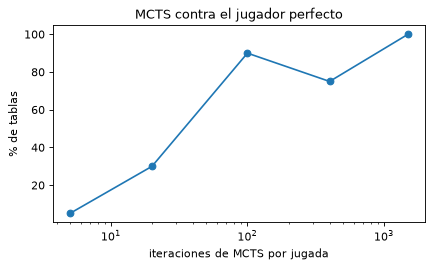

In [12]:
def jugador_perfecto(e):
    return min(jugadas_optimas(e))


def jugador_mcts(iteraciones, semilla, juego=tres):
    rng = random.Random(semilla)
    return lambda e: mcts(juego, e, iteraciones, rng)


lista_iteraciones = [5, 20, 100, 400, 1500]
tablas = []
print(f"{'iteraciones':>11} {'MCTS gana':>10} {'tablas':>7} {'MCTS pierde':>12}")
for it in lista_iteraciones:
    marcador = Counter()
    for k in range(20):
        if k % 2 == 0:
            r = jugar(tres, jugador_mcts(it, k), jugador_perfecto)
        else:
            r = -jugar(tres, jugador_perfecto, jugador_mcts(it, k))
        marcador[r] += 1
    assert marcador[1] == 0
    tablas.append(marcador[0] / 20 * 100)
    print(f"{it:>11} {marcador[1]:>10} {marcador[0]:>7} {marcador[-1]:>12}")
assert tablas[-1] == 100

fig, ax = plt.subplots()
ax.plot(lista_iteraciones, tablas, "o-")
ax.set_xscale("log")
ax.set_xlabel("iteraciones de MCTS por jugada")
ax.set_ylabel("% de tablas")
ax.set_title("MCTS contra el jugador perfecto")
plt.show()

## 12. MCTS en el Conecta 4

La misma función `mcts` sirve para el Conecta 4 sin cambiar nada: basta con la interfaz del juego. Enfrentar a MCTS con 1500 iteraciones contra el alfa-beta de profundidad 4 con evaluación, dos partidas cambiando quién empieza, y a MCTS contra el jugador aleatorio, que debería ganar siempre.

In [13]:
for k in range(2):
    mc = jugador_mcts(1500, 50 + k, conecta)
    if k == 0:
        r = jugar(conecta, mc, jugador_alfabeta(4))
    else:
        r = -jugar(conecta, jugador_alfabeta(4), mc)
    print(f"Partida {k + 1} (MCTS juega con {'X' if k == 0 else 'O'}):", {1: "gana MCTS", 0: "tablas", -1: "gana alfa-beta"}[r])

victorias = 0
for k in range(4):
    mc, azar = jugador_mcts(300, 60 + k, conecta), jugador_aleatorio(70 + k)
    victorias += (jugar(conecta, mc, azar) == 1) if k % 2 == 0 else (jugar(conecta, azar, mc) == -1)
print(f"MCTS (300 iteraciones) gana {victorias} de 4 al jugador aleatorio")
assert victorias == 4

Partida 1 (MCTS juega con X): gana alfa-beta


Partida 2 (MCTS juega con O): gana alfa-beta
MCTS (300 iteraciones) gana 4 de 4 al jugador aleatorio
